# Assignment 1: K-Means Clustering on Iris Dataset

In this assignment, we apply the K-Means clustering algorithm to the Iris dataset and visualize the resulting clusters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

## Load the Iris Dataset

The Iris dataset contains measurements of iris flowers such as sepal length, sepal width, petal length, and petal width.

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Feature names:", iris.feature_names)

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## Apply K-Means Clustering

We use K-Means with 3 clusters because the Iris dataset contains three flower species.

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X)

print("Cluster labels:")
print(clusters)

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


## Visualize the Clusters

The clusters are visualized using petal length and petal width.

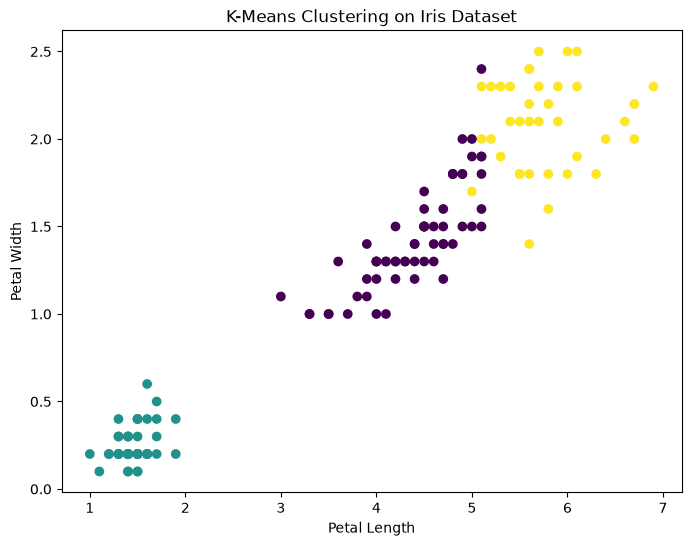

In [4]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=clusters
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clustering on Iris Dataset")

plt.show()

# Show Centroids

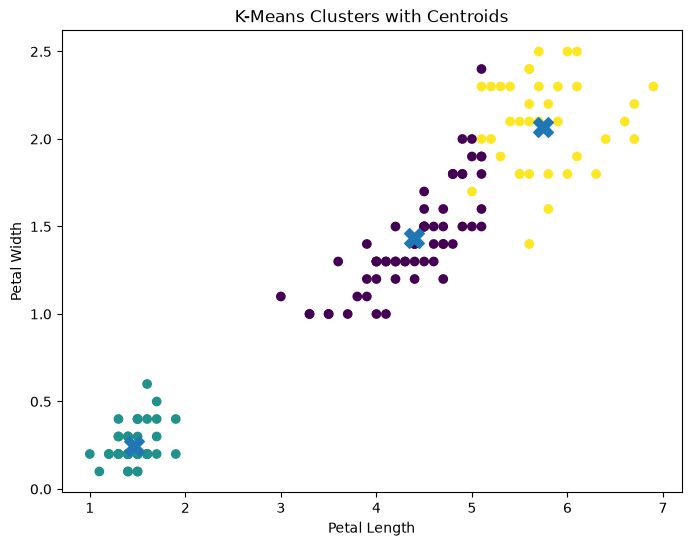

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=clusters
)

plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    marker="X",
    s=200
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clusters with Centroids")

plt.show()

# Assignment 2: PCA Dimensionality Reduction

Principal Component Analysis (PCA) is used to reduce the number of features in a dataset while preserving as much important information as possible.

## Load the Iris Dataset

We load the Iris dataset and store its four features in X before applying PCA.

In [3]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)

Dataset shape: (150, 4)


## Standardize the Dataset

Before applying PCA, the features are standardized so that all features have a comparable scale.

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled dataset shape:", X_scaled.shape)

Scaled dataset shape: (150, 4)


## Apply PCA

We reduce the original 4 features into 2 principal components.

In [5]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)

Original shape: (150, 4)
Reduced shape: (150, 2)


## Explained Variance

The explained variance shows how much information is retained by each principal component.

In [6]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance retained:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.72962445 0.22850762]
Total variance retained:
0.9581320720000164


## Visualize the PCA Results

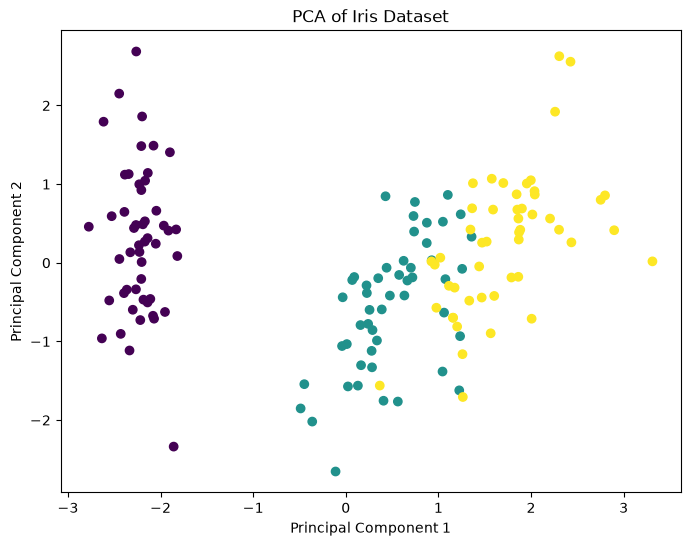

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Iris Dataset")

plt.show()

## Conclusion

K-Means successfully grouped the Iris dataset into three clusters. PCA reduced the original four-dimensional dataset to two dimensions while retaining most of the important information. The two principal components can be visualized to understand the distribution of the Iris data.

# Mini Project 3: Iris Flower Clustering Project

## Objective

The objective of this project is to apply the K-Means clustering algorithm
to the Iris dataset and group the flowers into three clusters.

### Tasks
- Apply K-Means clustering with k = 3
- Visualize the clusters using a scatter plot
- Compare predicted clusters with the true Iris labels

### Skill Gain
Unsupervised Machine Learning and Data Visualization

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix

## 1. Load the Iris Dataset

The Iris dataset contains 150 flower samples with four features:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

The dataset contains three species of Iris flowers.

In [9]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


## 2. Explore the Dataset

In [10]:
df = pd.DataFrame(X, columns=iris.feature_names)

df["True Label"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True Label
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3. Apply K-Means Clustering

K-Means is an unsupervised learning algorithm that divides the data into
a specified number of clusters.

Since the Iris dataset contains three species, we use k = 3.

In [11]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

predicted_clusters = kmeans.fit_predict(X)

print("Predicted cluster labels:")
print(predicted_clusters)

Predicted cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


## 4. Add Predicted Clusters to the Dataset

In [12]:
df["Predicted Cluster"] = predicted_clusters

df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True Label,Predicted Cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1
5,5.4,3.9,1.7,0.4,0,1
6,4.6,3.4,1.4,0.3,0,1
7,5.0,3.4,1.5,0.2,0,1
8,4.4,2.9,1.4,0.2,0,1
9,4.9,3.1,1.5,0.1,0,1


## 5. Visualize the K-Means Clusters

The clusters are visualized using Petal Length and Petal Width.

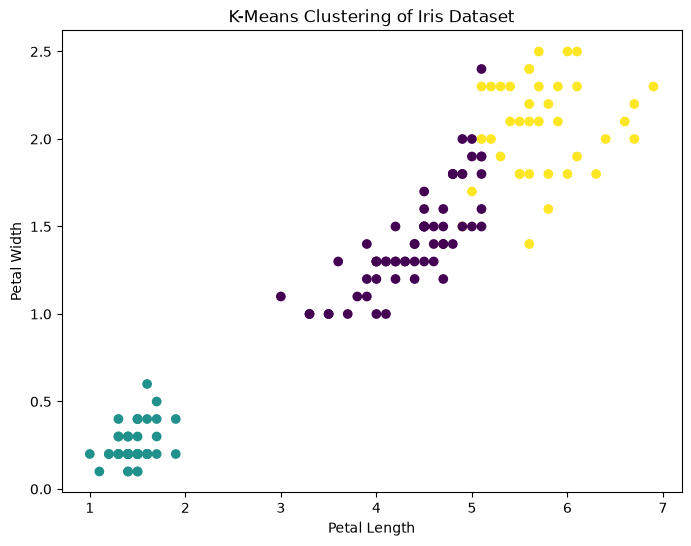

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=predicted_clusters
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clustering of Iris Dataset")

plt.show()

## 6. Visualize Clusters with Centroids

The X-shaped points represent the centroids calculated by the K-Means algorithm.

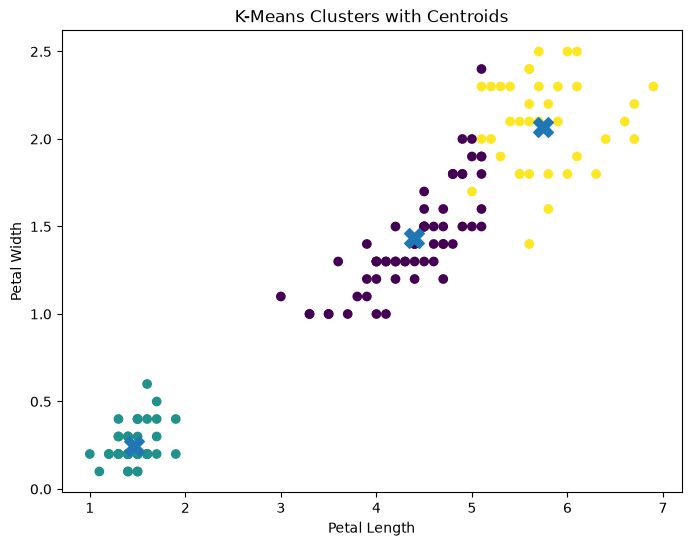

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=predicted_clusters
)

plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    marker="X",
    s=200
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clusters with Centroids")

plt.show()

## 7. Compare Predicted Clusters with True Labels

The Iris dataset provides the actual species labels.

We compare these true labels with the clusters generated by K-Means.

In [15]:
comparison = pd.DataFrame({
    "True Label": y,
    "Predicted Cluster": predicted_clusters
})

comparison.head(20)

,True Label,Predicted Cluster
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1
5,0,1
6,0,1
7,0,1
8,0,1
9,0,1


## 8. Confusion Matrix

In [16]:
cm = confusion_matrix(y, predicted_clusters)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 0 50  0]
 [48  0  2]
 [14  0 36]]


## 9. True Labels vs Predicted Clusters

The first plot shows the actual Iris labels, while the second plot shows
the clusters generated by K-Means.

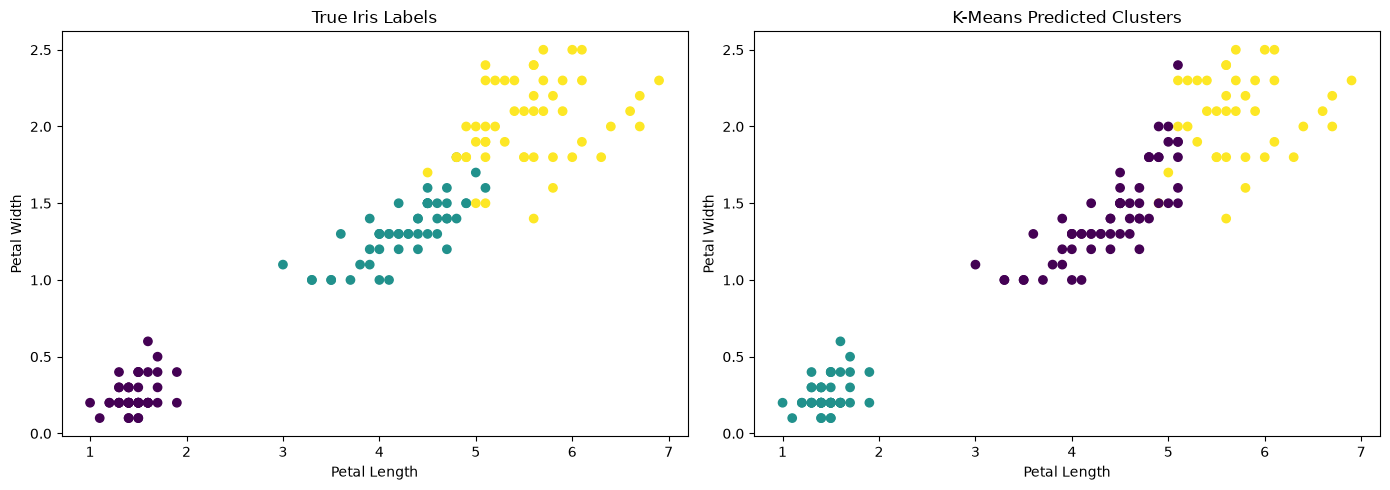

In [17]:
plt.figure(figsize=(14, 5))

# True labels
plt.subplot(1, 2, 1)

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=y
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("True Iris Labels")

# Predicted clusters
plt.subplot(1, 2, 2)

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=predicted_clusters
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Predicted Clusters")

plt.tight_layout()
plt.show()

## Conclusion

In this project, K-Means clustering was applied to the Iris dataset using
three clusters.

The generated clusters were visualized using Petal Length and Petal Width.
The predicted clusters were then compared with the true Iris labels.

The results show that K-Means can effectively separate the Iris flowers
into groups based on their feature similarities.

This project demonstrates the use of unsupervised machine learning for
clustering and data visualization.